  model        loglik      n       dll
0  base -12656.091390  77371  0.000000
1  full -12628.383258  77371  0.000358
2  lam1 -12648.956003  77371  0.000092
3  lam2 -12643.078100  77371  0.000168
4  lam4 -12644.142705  77371  0.000154
5  lam8 -12642.730976  77371  0.000173


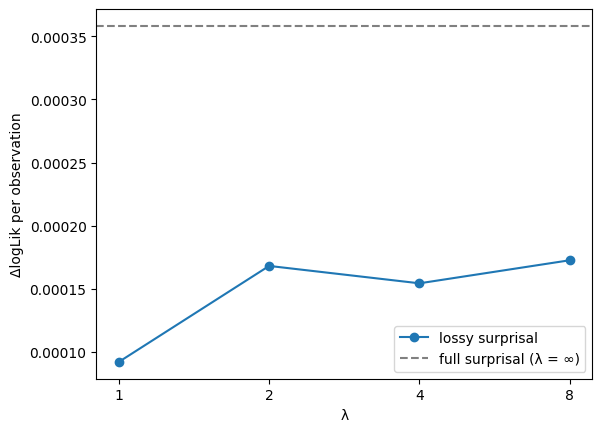

lambda_nat = 8
full / best lossy = 2.073897715541873


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../results/ns_loglik.csv")
base = df.loc[df.model == "base", "loglik"].iloc[0]
df["dll"] = (df.loglik - base) / df.n
print(df)

lam = {"lam1": 1, "lam2": 2, "lam4": 4, "lam8": 8}
lossy = df[df.model.isin(lam)]
full = df.loc[df.model == "full", "dll"].iloc[0]

plt.plot([lam[m] for m in lossy.model], lossy.dll, "o-", label="lossy surprisal")
plt.axhline(full, ls="--", color="gray", label="full surprisal (λ = ∞)")
plt.xscale("log", base=2)
plt.xticks([1, 2, 4, 8], ["1", "2", "4", "8"])
plt.xlabel("λ")
plt.ylabel("ΔlogLik per observation")
plt.legend()
plt.savefig("../figures/ns_dll_plot.pdf", dpi=200, bbox_inches="tight")
plt.show()

best = lossy.loc[lossy.dll.idxmax(), "model"]
print("lambda_nat =", lam[best])
print("full / best lossy =", full / lossy.dll.max())

ex 4

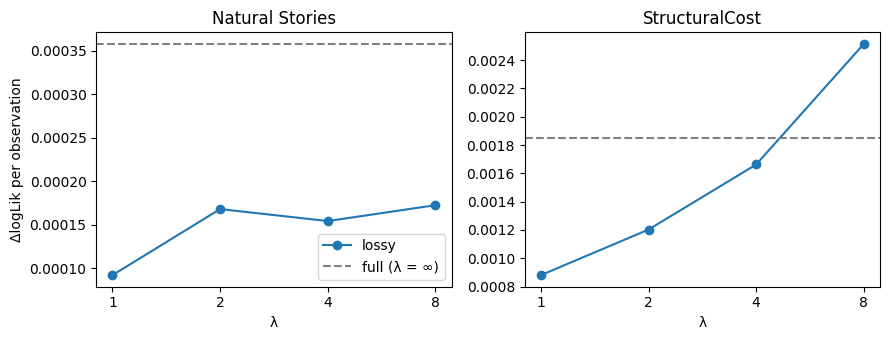

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

lam = {"lam1": 1, "lam2": 2, "lam4": 4, "lam8": 8}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, name, title in [(axes[0], "ns", "Natural Stories"),
                        (axes[1], "sc", "StructuralCost")]:
    df = pd.read_csv(f"../results/{name}_loglik.csv")
    base = df.loc[df.model == "base", "loglik"].iloc[0]
    df["dll"] = (df.loglik - base) / df.n
    lossy = df[df.model.isin(lam)]
    ax.plot([lam[m] for m in lossy.model], lossy.dll, "o-", label="lossy")
    ax.axhline(df.loc[df.model == "full", "dll"].iloc[0], ls="--",
               color="gray", label="full (λ = ∞)")
    ax.set_xscale("log", base=2)
    ax.set_xticks([1, 2, 4, 8]); ax.set_xticklabels(["1", "2", "4", "8"])
    ax.set_xlabel("λ"); ax.set_title(title)
axes[0].set_ylabel("ΔlogLik per observation")
axes[0].legend()
plt.tight_layout()
plt.savefig("../figures/both_dll_plot.png", dpi=200, bbox_inches="tight")